EDA 

**Цель** - изучить данные перед передачей их в модель

**Задачи**:

1. Первичный анализ данных (изучить типы, пропуски, дубликаты)
2. Понять какой дисбаланс классов
3. Посмотреть на корреляции для Feature Engineering

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None) 
pd.set_option("display.float_format", "{:.2f}".format) 
sns.set_theme(style="whitegrid", palette="muted") 
plt.rcParams["figure.figsize"] = (15, 10) 

## Загрузка данных

In [2]:
DATA_PATH = "../data/raw/UCI_Credit_Card.csv"

data = pd.read_csv(DATA_PATH)
data = data.rename(columns={"default.payment.next.month": "default"})
print(f"Размер датасета: {data.shape[0]} строк, {data.shape[1]} колонок")
data.head()

Размер датасета: 30000 строк, 25 колонок


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000.00,2,2,1,24,2,2,-1,-1,-2,-2,3913.00,3102.00,689.00,0.00,0.00,0.00,0.00,689.00,0.00,0.00,0.00,0.00,1
1,2,120000.00,2,2,2,26,-1,2,0,0,0,2,2682.00,1725.00,2682.00,3272.00,3455.00,3261.00,0.00,1000.00,1000.00,1000.00,0.00,2000.00,1
2,3,90000.00,2,2,2,34,0,0,0,0,0,0,29239.00,14027.00,13559.00,14331.00,14948.00,15549.00,1518.00,1500.00,1000.00,1000.00,1000.00,5000.00,0
3,4,50000.00,2,2,1,37,0,0,0,0,0,0,46990.00,48233.00,49291.00,28314.00,28959.00,29547.00,2000.00,2019.00,1200.00,1100.00,1069.00,1000.00,0
4,5,50000.00,1,2,1,57,-1,0,-1,0,0,0,8617.00,5670.00,35835.00,20940.00,19146.00,19131.00,2000.00,36681.00,10000.00,9000.00,689.00,679.00,0


## Первичный анализ данных

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         30000 non-null  int64  
 1   LIMIT_BAL  30000 non-null  float64
 2   SEX        30000 non-null  int64  
 3   EDUCATION  30000 non-null  int64  
 4   MARRIAGE   30000 non-null  int64  
 5   AGE        30000 non-null  int64  
 6   PAY_0      30000 non-null  int64  
 7   PAY_2      30000 non-null  int64  
 8   PAY_3      30000 non-null  int64  
 9   PAY_4      30000 non-null  int64  
 10  PAY_5      30000 non-null  int64  
 11  PAY_6      30000 non-null  int64  
 12  BILL_AMT1  30000 non-null  float64
 13  BILL_AMT2  30000 non-null  float64
 14  BILL_AMT3  30000 non-null  float64
 15  BILL_AMT4  30000 non-null  float64
 16  BILL_AMT5  30000 non-null  float64
 17  BILL_AMT6  30000 non-null  float64
 18  PAY_AMT1   30000 non-null  float64
 19  PAY_AMT2   30000 non-null  float64
 20  PAY_AM

In [4]:
data.isna().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
default      0
dtype: int64

In [5]:
data.duplicated().sum()

0

В данном датасете все признаки числовые (даже категориальные закодированы числами), что упрощает препроцессинг будет использоваться только  OneHotEncoder для номинальных. Пропусков и явных дубликатов нет.

## Дисбаланс классов

default
0    23364
1     6636
Name: count, dtype: int64

Доли классов (%):
default
0   77.88
1   22.12
Name: proportion, dtype: float64


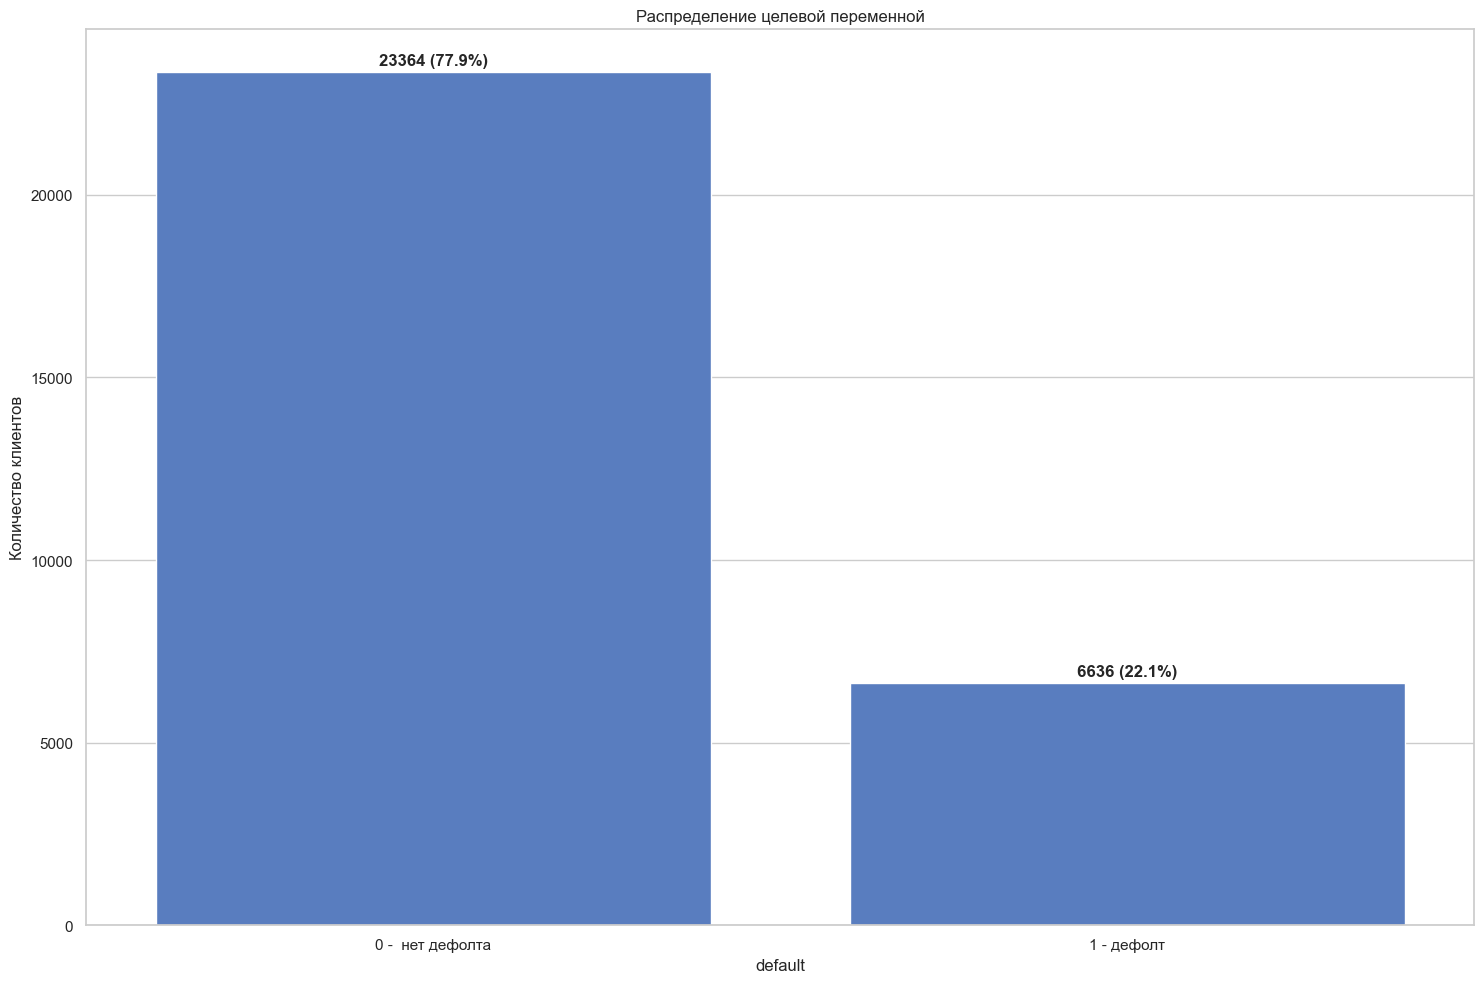

In [6]:
target_counts = data["default"].value_counts().sort_index()
print(target_counts)

target_pct = data["default"].value_counts(normalize=True).sort_index() * 100
print("\nДоли классов (%):")
print(target_pct.round(2))

fig, ax = plt.subplots(figsize=(15, 10))
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax)
ax.set_xticklabels(["0 -  нет дефолта", "1 - дефолт"])
ax.set_ylabel("Количество клиентов")
ax.set_title("Распределение целевой переменной")
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 200, f"{v} ({target_pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

У 22% наблюдается дефолт, виден умеренный дисбаланс классов. Поэтому accuracy не будет использоваться. Возьмем ROC-AUC, которая устойчива к дисбалансу, оценивает качество ранжирования и Precision / Recall / F1 - для класса "дефолт" (класс 1). Для обучения попробуем потом class_weight="balanced" или SMOTE.

## Описательные статистики

In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.00,15000.50,8660.40,1.00,7500.75,15000.50,22500.25,30000.00
LIMIT_BAL,30000.00,167484.32,129747.66,10000.00,50000.00,140000.00,240000.00,1000000.00
SEX,30000.00,1.60,0.49,1.00,1.00,2.00,2.00,2.00
EDUCATION,30000.00,1.85,0.79,0.00,1.00,2.00,2.00,6.00
MARRIAGE,30000.00,1.55,0.52,0.00,1.00,2.00,2.00,3.00
AGE,30000.00,35.49,9.22,21.00,28.00,34.00,41.00,79.00
PAY_0,30000.00,-0.02,1.12,-2.00,-1.00,0.00,0.00,8.00
PAY_2,30000.00,-0.13,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_3,30000.00,-0.17,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_4,30000.00,-0.22,1.17,-2.00,-1.00,0.00,0.00,8.00


Для LIMIT_BAL распределение скошено вправо (есть клиенты с очень большим лимитом), нужно будет использовать StandardScaler. По возрасту основная масса людей от 21 до 40 лет. В BILL_AMT1...BILL_AMT6 есть отрицательные значения - клиенты у которых переплата по карте. PAY_AMT1...PAY_AMT6 скошены, много клиентов, которые не платили. 

## Распределения ключевых числовых признаков

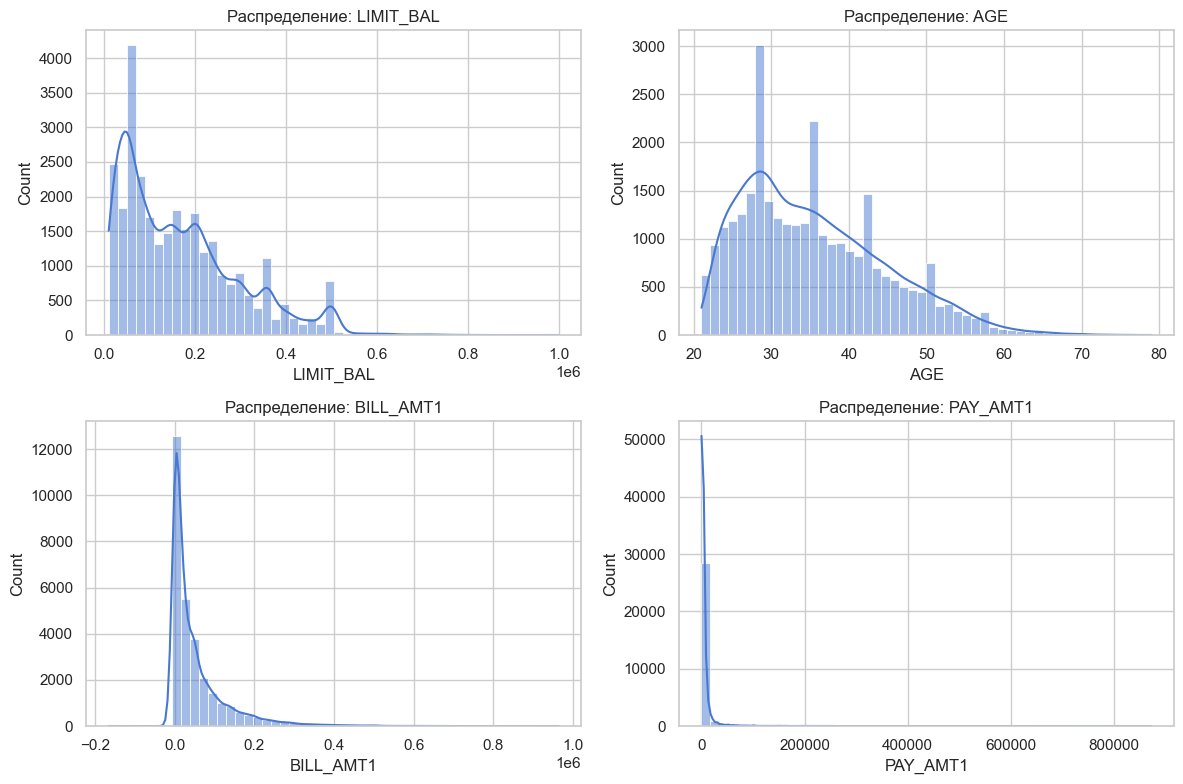

In [8]:
key_numeric = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(key_numeric):
    sns.histplot(data[col], kde=True, bins=50, ax=axes[i])
    axes[i].set_title(f"Распределение: {col}")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

Для ключевых признаков наблюдается скошенность, поэтому в пайплайне будем использовать StandardScaler, который приводит к нулевому среднему и единичной дисперсии.

## Категориальные признаки

In [9]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{col} — уникальные значения:")
    print(data[col].value_counts().sort_index())


SEX — уникальные значения:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION — уникальные значения:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE — уникальные значения:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


SEX: 1 = male, 2 = female.

EDUCATION: 1 = graduate school, 2 = university, 3 = high school, 4 = others, 0, 5, 6 = unknown.

MARRIAGE: 1 = married, 2 = single, 3 = others.

В данных есть недокументированные значения (EDUCATION=0,5,6, MARRIAGE=0). Это пример "аномалий", которые можно обнаружить в Great Expectations.

In [10]:
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

for col in pay_cols[:3]:  
    print(f"\n{col}:")
    print(data[col].value_counts().sort_index())


PAY_0:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2:
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3:
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64


Вместо отдельных колонок можно создать агрегированные признаки. Например, максимальная задержка, средняя задержка, сколько раз платеж просрочен

## Матрица корреляций

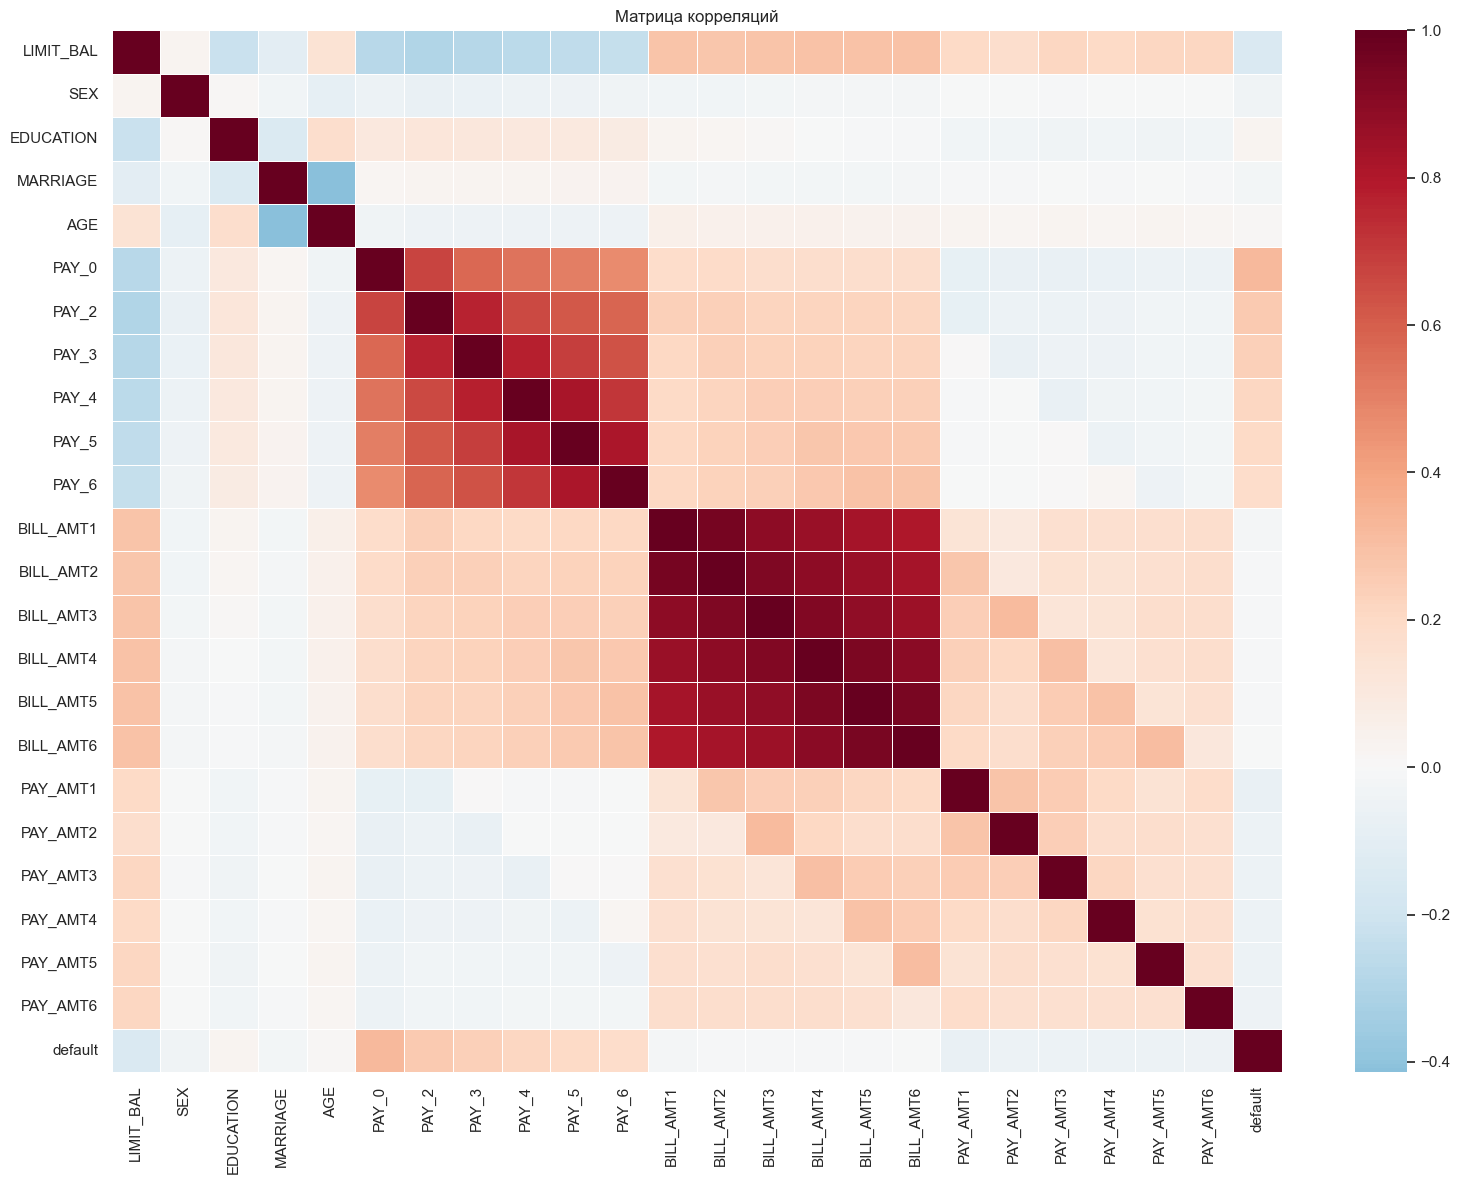

Топ-10 признаков по корреляции с default:
PAY_0        0.32
PAY_2        0.26
PAY_3        0.24
PAY_4        0.22
PAY_5        0.20
PAY_6        0.19
LIMIT_BAL   -0.15
PAY_AMT1    -0.07
PAY_AMT2    -0.06
PAY_AMT4    -0.06
Name: default, dtype: float64


In [11]:
corr = data.drop(columns=["ID"]).corr(numeric_only=True)

plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, linewidths=0.5, annot=False)
plt.title("Матрица корреляций")
plt.tight_layout()
plt.show()

target_corr = corr["default"].drop("default").sort_values(key=abs, ascending=False)
print("Топ-10 признаков по корреляции с default:")
print(target_corr.head(10))

PAY_0...PAY_6, как и BILL_AMT1...BILL_AMT6 сильно коррелируют между собой (мультиколлинеарность). С целевой переменной сильнее всего коррелируют PAY_0...PAY_6 (если человек задерживал платеж, вероятность дефолта больше). Для деревьев можно оставить всё как есть, но для логистической регрессии стоит убрать сильно коррелирующие признаки или применить PCA.

## Основные выводы по EDA

Размер датасета: 30000 строк, 25 колонок, все признаки числовые. Пропусков и явных дубликатов нет. Наблюдается умеренный дисбаланс классов, основные метрики: ROC-AUC (основная), Precision/Recall/F1 для класса 1. 

Аномалии:
   - EDUCATION: значения 0, 5, 6 (недокументированные) → обработать в build_features.
   - MARRIAGE: значение 0 (недокументированное).

Для Feature Engineering можно агрегировать  PAY_0...6